# DSA 4060XA – Recommender Systems
## Week 6 Guided Practical Lab: Evaluating Recommender Systems

**Models compared:** Popularity Baseline, Content-Based Filtering, and Item-Based Collaborative Filtering  
**Evaluation focus:** Rating prediction, Top-N ranking quality, catalogue coverage, novelty, and diversity  
**Top-N cutoff:** `K = 3`

### Student details
- **Student name:** Halima Mahdi Mohammed
- **Student ID:** 670315

> **Important:** This notebook uses the two CSV files supplied for the Week 6 lab. Keep both CSV files in the same folder as this notebook, or update the file paths in Step 2. Run every cell from top to bottom after restarting the kernel before submitting.

## Lab objective

The objective is to build and evaluate three recommendation approaches using a consistent train/test split. The popularity baseline provides a simple reference point. The content-based recommender uses movie genres and a user's observed ratings to estimate preference. The item-based collaborative-filtering recommender uses patterns in how users rate the same movies.

The lab deliberately evaluates more than one dimension of quality. **MAE and RMSE** measure rating prediction error, while **Precision@3, Recall@3, and NDCG@3** measure aspects of ranked recommendation quality. **Coverage, novelty, and diversity** help identify whether recommendations are concentrated on a small group of popular items or expose users to a wider range of the catalogue.

## Evaluation principles

1. **Use unseen interactions.** The test interaction is held out and must not be used to construct training profiles, item averages, or item similarities.
2. **Compare against a baseline.** A more complex model should demonstrate a meaningful advantage over a transparent, simple method.
3. **Match metrics to the objective.** A low rating-prediction error does not automatically mean that the model creates the best Top-N list.
4. **Interpret trade-offs.** Accuracy, discovery, explainability, coverage, novelty, and diversity can pull in different directions.
5. **Avoid unsupported conclusions.** The data are a small teaching dataset, so results should be treated as illustrative rather than evidence of production performance.

## Step 1 – Import the required libraries

We use:
- `pandas` to load and manipulate tabular data;
- `NumPy` for numerical operations and logarithms;
- `matplotlib` to visualise rating behaviour;
- `scikit-learn` to calculate MAE, RMSE, and cosine similarity.

`TOP_K = 3` means each ranking model will return up to three unseen movies per user. We set a random seed for reproducibility, although this lab's chronological split is deterministic and does not use random sampling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 3
RANDOM_SEED = 42

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

print("Libraries imported successfully.")
print("Top-K cutoff:", TOP_K)

Libraries imported successfully.
Top-K cutoff: 3


## Step 2 – Load and inspect the data

The **movies** table contains item metadata: one row per movie, its unique identifier, title, and genre labels. The **ratings** table contains user–movie interactions: one row represents one user's rating of one movie at a recorded timestamp.

The rating is **explicit feedback** because the user directly provides a numerical score. The supplied scale is 1–5, where higher values indicate a more positive rating. The timestamp is used to order interactions chronologically within each user.

The checks below confirm the file contents and basic data quality before modelling.

In [2]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")

display(movies.head())
display(ratings.head())

print("Movie rows:", len(movies))
print("Unique users:", ratings["user_id"].nunique())
print("Unique movies rated:", ratings["movie_id"].nunique())
print("Rating interactions:", len(ratings))
print("Rating scale observed:", sorted(ratings["rating"].dropna().unique()))
print("Missing values in movies:\n", movies.isna().sum())
print("Missing values in ratings:\n", ratings.isna().sum())

# Basic consistency checks: every rating should refer to a movie in the catalogue.
unknown_movie_ids = set(ratings["movie_id"]) - set(movies["movie_id"])
print("Rating rows referring to unknown movie IDs:", len(unknown_movie_ids))

assert movies["movie_id"].is_unique, "movie_id should uniquely identify each movie."
assert not ratings[["user_id", "movie_id", "rating", "timestamp"]].isna().any().any(), "Ratings contain missing required values."
assert not unknown_movie_ids, "Some ratings refer to movie IDs absent from the movies catalogue."

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Movie rows: 20
Unique users: 12
Unique movies rated: 20
Rating interactions: 120
Rating scale observed: [np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Missing values in movies:
 movie_id    0
title       0
genres      0
dtype: int64
Missing values in ratings:
 user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64
Rating rows referring to unknown movie IDs: 0


### Student Check – Data inspection

1. **What does one row in `movies` represent?** One movie and its metadata.
2. **What does one row in `ratings` represent?** One user's explicit rating of one movie at a timestamp.
3. **How many unique users and movies are present?** Read the counts printed above; note that the number of movies in the catalogue may differ from the number of movies that received ratings.
4. **What type of feedback is the rating column?** Explicit feedback.
5. **What is the rating scale?** The supplied dataset uses a 1–5 scale.

**Interpretation note:** In a report, distinguish the number of movies in the full catalogue from the number of movies that appear in the ratings interactions. This matters when calculating catalogue coverage.

## Step 3 – Inspect rating behaviour

Before modelling, examine the distribution of ratings. A dataset dominated by high ratings may make it easier for a model to appear accurate if it predicts ratings near the overall average. Rating imbalance can also affect the number of test interactions considered relevant.

The bar chart shows the number of occurrences of each rating value. Use the displayed counts to write a short interpretation of whether high or low ratings dominate.

,count
rating,
2,29
3,49
4,28
5,14


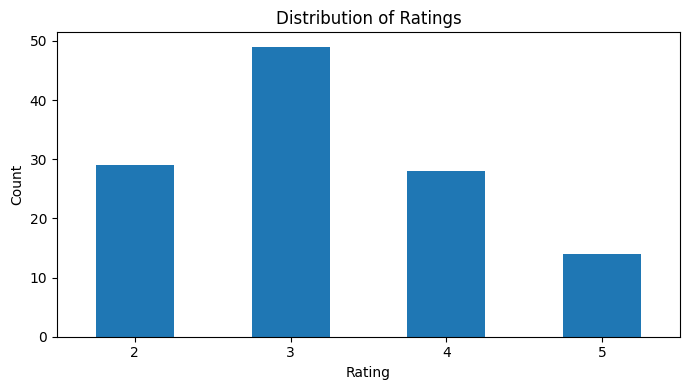

Mean rating: 3.225
Median rating: 3.0


In [3]:
rating_counts = ratings["rating"].value_counts().sort_index()
display(rating_counts.rename("count").to_frame())

plt.figure(figsize=(7, 4))
rating_counts.plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Mean rating:", round(ratings["rating"].mean(), 3))
print("Median rating:", ratings["rating"].median())

### Interpretation – Rating distribution

Use the output above to complete the following in your own words:

- The most common rating is **[insert rating]**, occurring **[insert count]** times.
- Ratings of 4 or 5 account for **[calculate from the table]** of all interactions.
- If positive ratings dominate, a recommender may appear useful simply by favouring popular or generally well-rated movies. The relevance threshold used later (`rating >= 4`) also means the ranking metrics depend on how many held-out interactions are positive.

Do not write that high or low ratings dominate until you have checked the actual chart and counts.

## Step 4 – Create a chronological train/test split

For each user, the interaction with the latest timestamp is held out as that user's test interaction. All earlier interactions from that user are used for training. This preserves a training history for users who have at least two interactions and approximates the practical question: **given what was known earlier, can the model estimate or recommend the later interaction?**

Using an interaction in both training and testing would leak information and make evaluation overly optimistic. The split below is deterministic. If multiple interactions for a user share the same timestamp, the original row order may determine which tied row is selected; a production evaluation should define a tie-breaking rule.

The lab assumes each user has enough interactions to leave at least one in training. We check that assumption below.

In [4]:
ratings = ratings.sort_values(["user_id", "timestamp"]).copy()

test = ratings.groupby("user_id").tail(1).copy()
train = ratings.drop(index=test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))
print("Users in training:", train["user_id"].nunique())
print("Users in test:", test["user_id"].nunique())
print("Users with no training history:", len(set(test["user_id"]) - set(train["user_id"])))

assert set(train.index).isdisjoint(set(test.index)), "Train and test rows overlap."
assert len(train) + len(test) == len(ratings), "Train/test split does not account for all rows."
assert train.groupby("user_id").size().min() >= 1, "At least one user has no training history."
display(test.head())

Training interactions: 108
Test interactions: 12
Users in training: 12
Users in test: 12
Users with no training history: 0


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


## Step 5 – Build the popularity baseline

A baseline is a transparent reference that more complex approaches should be compared against. This lab uses two related popularity-baseline behaviours:

- **Rating prediction:** predict a movie's mean rating from training data. If a movie has no training rating, use the global mean of all training ratings.
- **Top-N ranking:** sort movies by their training mean rating, breaking ties using the number of training ratings. The rating-count tie-break helps favour movies with more evidence when average ratings are identical, but it is not a statistically adjusted estimate.

The global mean and movie averages are calculated from **training data only**. The held-out test ratings are not used to build the baseline.

In [5]:
global_mean = train["rating"].mean()

movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id", how="right")
)

# Movies without training ratings receive the global mean for prediction.
movie_stats["mean_rating"] = movie_stats["mean_rating"].fillna(global_mean)
movie_stats["rating_count"] = movie_stats["rating_count"].fillna(0).astype(int)

display(
    movie_stats.sort_values(
        ["mean_rating", "rating_count"],
        ascending=[False, False]
    ).head(10)
)

movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()

baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)

print("Global training mean:", round(global_mean, 3))
display(baseline_test[["user_id", "movie_id", "rating", "prediction"]].head())

,movie_id,mean_rating,rating_count,title
5,6,4.166667,6,Broken Hearts
0,1,4.000000,3,Galaxy Mission
17,18,4.000000,2,The Promise
3,4,3.800000,5,Family Weekend
9,10,3.666667,6,Hidden Truth
15,16,3.571429,7,Campus Life
6,7,3.500000,8,City Detectives
12,13,3.400000,5,Digital Dreams
18,19,3.250000,4,Night Chase
2,3,3.166667,6,Final Battle


Global training mean: 3.222


,user_id,movie_id,rating,prediction
9,1,14,4,2.857143
19,2,9,4,3.000000
29,3,18,3,4.000000
39,4,18,3,4.000000
49,5,11,2,2.500000


## Step 6 – Evaluate rating prediction with MAE and RMSE

**Mean Absolute Error (MAE)** is the mean of the absolute differences between actual and predicted ratings. If MAE is 0.70, the prediction differs from the actual rating by 0.70 rating points on average.

**Root Mean Squared Error (RMSE)** squares errors before averaging and then takes the square root. This gives larger errors more influence than MAE.

Both metrics are measured in rating points, and **lower is better**. They answer related but different questions, so report both rather than selecting a model from only one metric.

In [6]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


## Step 7 – Build item features for content-based filtering

The content-based model represents each movie using its genre labels. `str.get_dummies(sep="|")` creates a binary column for each genre. For example, a movie labelled `Action|Sci-Fi` receives a 1 in the Action column and a 1 in the Sci-Fi column, and 0 in other genre columns.

This representation is simple and interpretable, but it ignores other potentially useful item features such as cast, director, language, description, release date, and user context. It also treats all genre labels as equally informative.

In [7]:
genre_features = movies["genres"].fillna("").str.get_dummies(sep="|")

content_items = pd.concat(
    [movies[["movie_id", "title"]].reset_index(drop=True),
     genre_features.reset_index(drop=True)],
    axis=1
)

genre_columns = genre_features.columns.tolist()
item_feature_matrix = pd.concat(
    [movies[["movie_id"]].reset_index(drop=True),
     genre_features.reset_index(drop=True)],
    axis=1
).set_index("movie_id")[genre_columns]

display(content_items.head())
print("Number of genre features:", len(genre_columns))
print("Genre features:", genre_columns)

,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


Number of genre features: 9
Genre features: ['Action', 'Adventure', 'Comedy', 'Crime', 'Drama', 'Family', 'Mystery', 'Romance', 'Sci-Fi']


## Step 8 – Build a user preference profile

For each user, the model retrieves the movies they rated in the training set. It multiplies each movie's binary genre vector by that user's rating, then averages the weighted vectors. The resulting vector represents a simple genre-preference profile.

A larger value for a genre indicates that the user's training history gives that genre a larger weighted contribution. Because raw ratings are used as weights, this approach does not centre ratings around each user's personal average; a rating of 3 still contributes positively to a genre. That is a deliberate simplification for this guided lab.

**Student task:** Inspect User 1's profile and identify their two strongest genre features. Compare these with the genres of their highly rated training movies.

In [8]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]

    if history.empty:
        return np.zeros(len(genre_columns), dtype=float)

    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values

    return (features * ratings_array).mean(axis=0)

profile = build_user_profile(1, train)

user_1_profile = pd.Series(profile, index=genre_columns).sort_values(ascending=False)
display(user_1_profile.to_frame("weighted_profile_score"))

user_1_history = train[train["user_id"] == 1].merge(
    movies[["movie_id", "title", "genres"]], on="movie_id", how="left"
).sort_values("rating", ascending=False)
display(user_1_history)

,weighted_profile_score
Drama,1.666667
Sci-Fi,1.000000
Comedy,0.888889
Romance,0.666667
Action,0.555556
Family,0.555556
Crime,0.333333
Mystery,0.333333
Adventure,0.222222


,user_id,movie_id,rating,timestamp,title,genres
2,1,1,5,3,Galaxy Mission,Action|Sci-Fi
6,1,13,4,7,Digital Dreams,Sci-Fi|Drama
0,1,2,3,1,Love in Nairobi,Romance|Drama
3,1,9,3,4,Wedding Weekend,Romance|Comedy
1,1,10,3,2,Hidden Truth,Drama|Mystery
4,1,7,3,5,City Detectives,Crime|Drama
8,1,4,3,9,Family Weekend,Comedy|Family
5,1,15,2,6,Home Again,Family|Drama
7,1,20,2,8,Weekend Escape,Comedy|Adventure


## Step 9 – Content-based rating prediction

The content-based model compares a user's preference profile with a candidate movie's genre vector using **cosine similarity**. Cosine similarity is higher when the vectors point in a similar direction. For this teaching lab, similarity is converted to a rough 1–5 prediction using `1 + 4 × similarity`, clipped to the rating scale.

This conversion is a heuristic, not a learned rating-calibration model. A cosine similarity of zero maps to 1 and a similarity of one maps to 5, even though those values may not reflect how real users use the rating scale. The MAE and RMSE results should therefore be interpreted with this limitation in mind.

In [9]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)

    if np.linalg.norm(profile) == 0 or np.linalg.norm(item_vec) == 0:
        return float(global_mean)

    sim = cosine_similarity(profile, item_vec)[0, 0]
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train),
    axis=1
)

content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


## Step 10 – Build item-based collaborative filtering

Collaborative filtering uses interaction patterns rather than movie metadata. In item-based collaborative filtering, movies are considered similar when their user-rating patterns are similar. To build these patterns, the training data are converted into a user–item matrix: rows are users, columns are movies, and observed cells contain ratings.

The lab fills missing ratings with zero before computing cosine similarity. This is easy to demonstrate, but zero is not a valid rating on the supplied 1–5 scale. Consequently, similarity is influenced by which users did or did not rate each movie. More advanced implementations can calculate similarities using co-rated users and minimum-support thresholds, or use mean-centred ratings.

In [10]:
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

display(item_similarity.iloc[:5, :5])
print("User-item matrix shape:", user_item.shape)
print("Item similarity matrix shape:", item_similarity.shape)

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


User-item matrix shape: (12, 20)
Item similarity matrix shape: (20, 20)


## Step 11 – Item-based rating prediction

For a target movie, the model looks at the movies already rated by the user. It retrieves the similarity between the target and each movie in the user's history, then calculates a similarity-weighted average of the user's ratings. Only positive similarities are used. If no positive similarity is available, the global training mean is returned.

The model uses only training interactions to construct the user history and item similarity matrix. This prevents the held-out rating from directly influencing the prediction.

In [11]:
def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]

    weighted_sum = 0.0
    similarity_sum = 0.0

    if movie_id not in item_similarity.index:
        return float(global_mean)

    for row in history.itertuples():
        if row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]

            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim

    if similarity_sum == 0:
        return float(global_mean)

    return float(weighted_sum / similarity_sum)

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train),
    axis=1
)

cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

print("Item-Based CF MAE:", round(cf_mae, 3))
print("Item-Based CF RMSE:", round(cf_rmse, 3))

Item-Based CF MAE: 0.924
Item-Based CF RMSE: 1.07


## Step 12 – Compare rating-prediction metrics

The table compares the three models on the same held-out interactions. The model with the lowest MAE has the smallest average absolute rating error; the model with the lowest RMSE has the smallest root-mean-squared error and is less tolerant of occasional large errors.

Answer these questions using your results:

6. Which model has the lowest MAE?
7. Which model has the lowest RMSE?
8. Does either advanced model clearly beat the baseline?
9. Why should you avoid declaring a model best from only one metric?

A difference in the third decimal place may not be meaningful on such a small dataset. Consider the magnitude of differences and the limitations of the split.

,Model,MAE,RMSE
2,Item-Based CF,0.924,1.070
0,Popularity Baseline,1.086,1.201
1,Content-Based,1.094,1.381


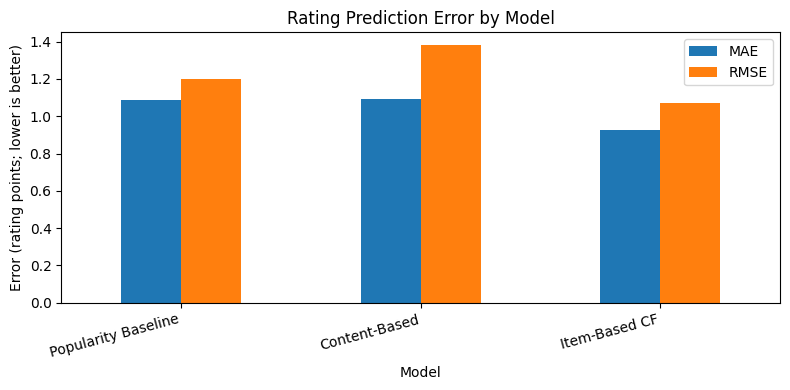

In [12]:
rating_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

display(rating_results.sort_values("MAE").round(3))

rating_plot = rating_results.set_index("Model")[["MAE", "RMSE"]]
rating_plot.plot(kind="bar", figsize=(8, 4))
plt.title("Rating Prediction Error by Model")
plt.ylabel("Error (rating points; lower is better)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Step 13 – Define relevance for ranking evaluation

Many recommender systems are designed to place useful items near the top of a short list, rather than predict an exact rating. For this lab, a held-out movie is considered **relevant if its actual rating is 4 or 5**.

Because this split holds out only one interaction per user, each user can have at most one relevant test item. Users whose held-out rating is below 4 have no relevant test item and are excluded from the macro-averaged ranking metrics below. This makes the metrics easy to demonstrate, but it also limits how much ranking quality can be measured.

In [13]:
test["relevant"] = test["rating"] >= 4
display(test[["user_id", "movie_id", "rating", "relevant"]].head(10))
print("Users with relevant held-out item:", test.loc[test["relevant"], "user_id"].nunique())
print("Users with non-relevant held-out item:", test.loc[~test["relevant"], "user_id"].nunique())

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False
59,6,2,5,True
69,7,3,2,False
79,8,12,2,False
89,9,16,2,False
99,10,19,3,False


Users with relevant held-out item: 5
Users with non-relevant held-out item: 7


## Step 14 – Build Top-N recommendation functions

Each recommender must exclude movies that the user has already rated in the training data. This is important because a system should generally recommend unseen catalogue items rather than simply return items already in the user's history.

- **Popularity:** recommends unseen movies in descending order of training mean rating, with rating count as the tie-break.
- **Content-based:** scores unseen movies by similarity to the user's genre profile.
- **Item-based CF:** predicts ratings for unseen movies using the item-similarity model, then sorts by predicted rating.

These functions return movie IDs. The next cell also displays titles so that the lists can be interpreted by a person.

In [14]:
all_movie_ids = movies["movie_id"].tolist()

def unseen_movies(user_id):
    seen = set(train.loc[train["user_id"] == user_id, "movie_id"])
    return [m for m in all_movie_ids if m not in seen]

popularity_order = (
    movie_stats.sort_values(
        ["mean_rating", "rating_count"],
        ascending=[False, False]
    )["movie_id"].tolist()
)

def recommend_popularity(user_id, k=TOP_K):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=TOP_K):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, score in scored[:k]]

def recommend_cf(user_id, k=TOP_K):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, score in scored[:k]]

def recommendation_titles(recommender, user_id, k=TOP_K):
    rec_ids = recommender(user_id, k)
    return movies[movies["movie_id"].isin(rec_ids)].set_index("movie_id").loc[rec_ids].reset_index()

for model_name, recommender in [
    ("Popularity", recommend_popularity),
    ("Content-Based", recommend_content),
    ("Item-Based CF", recommend_cf)
]:
    print(f"\n{model_name} recommendations for User 1:")
    display(recommendation_titles(recommender, 1))


Popularity recommendations for User 1:


,movie_id,title,genres
0,6,Broken Hearts,Drama|Romance
1,18,The Promise,Romance|Drama
2,16,Campus Life,Comedy|Drama



Content-Based recommendations for User 1:


,movie_id,title,genres
0,16,Campus Life,Comedy|Drama
1,6,Broken Hearts,Drama|Romance
2,18,The Promise,Romance|Drama



Item-Based CF recommendations for User 1:


,movie_id,title,genres
0,12,The Last Case,Mystery|Crime
1,11,Laugh Out Loud,Comedy
2,18,The Promise,Romance|Drama


### Discussion – Comparing recommendation lists

- **Which appears most personalised?** The content-based and collaborative-filtering lists can change according to a user's profile or history, while the popularity ranking is largely shared across users (apart from removing already-seen movies).
- **Which is easiest to explain?** The popularity baseline can be explained through average rating and rating count. Content-based recommendations can also be explained using shared genres. Item-based CF requires explaining similarity in historical rating patterns.
- **Important qualification:** A list that looks personalised is not automatically more relevant. The ranking metrics and the actual titles should both be examined.

## Step 15 – Calculate Precision@K, Recall@K, and NDCG@K

The three ranking metrics focus on different aspects of a recommendation list:

- **Precision@K:** the fraction of the first K recommendations that are relevant. Higher is better.
- **Recall@K:** the fraction of all relevant test items that appear in the first K recommendations. Higher is better.
- **NDCG@K:** rewards relevant items more when they appear nearer the top of the list. Higher is better.

For binary relevance, a hit contributes `1 / log2(rank + 1)` to DCG. NDCG divides this by the ideal DCG for the number of relevant items available. Since this lab has one held-out interaction per user, recall is either 1 (if the relevant item is retrieved) or 0 (if it is not), for users included in evaluation.

In [15]:
def precision_recall_at_k(recs, relevant, k):
    recs = recs[:k]
    hits = len(set(recs) & set(relevant))
    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan
    return precision, recall

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0
    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)

    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=TOP_K):
    rows = []

    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[
            (test["user_id"] == user_id) & (test["rating"] >= 4),
            "movie_id"
        ].tolist()

        if not relevant:
            continue

        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)

        rows.append({
            "user_id": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })

    result = pd.DataFrame(rows)
    if result.empty:
        return {"Precision@3": np.nan, "Recall@3": np.nan, "NDCG@3": np.nan}

    return {
        f"Precision@{k}": result["Precision@K"].mean(),
        f"Recall@{k}": result["Recall@K"].mean(),
        f"NDCG@{k}": result["NDCG@K"].mean()
    }

pop_rank = evaluate_ranking(recommend_popularity, TOP_K)
content_rank = evaluate_ranking(recommend_content, TOP_K)
cf_rank = evaluate_ranking(recommend_cf, TOP_K)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank}
])

display(ranking_results.round(3))

,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.067,0.2,0.1
1,Content-Based,0.067,0.2,0.2
2,Item-Based CF,0.000,0.0,0.0


## Step 16 – Catalogue coverage

**Catalogue coverage** is the proportion of all catalogue movies that appear in at least one user's Top-K recommendation list. It measures how much of the available catalogue the recommender exposes.

A high coverage score can support discovery, but it does not prove that the recommendations are relevant. A model could achieve high coverage by recommending many different but unhelpful items. Coverage must therefore be considered alongside ranking quality.

In [16]:
def catalogue_coverage(recommender, k=TOP_K):
    recommended = set()
    for user_id in sorted(train["user_id"].unique()):
        recommended.update(recommender(user_id, k))
    return len(recommended) / movies["movie_id"].nunique()

coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [
        catalogue_coverage(recommend_popularity, TOP_K),
        catalogue_coverage(recommend_content, TOP_K),
        catalogue_coverage(recommend_cf, TOP_K)
    ]
})

display(coverage_results.round(3))

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


## Step 17 – Novelty

**Novelty** estimates how surprising or less common a recommendation is. For this lab, item popularity is represented by the proportion of training users who rated the item. The item novelty score is `-log2(p)`, where `p` is that proportion. An item interacted with by fewer users receives a larger score.

Using the number of **distinct users** who rated each movie keeps `p` between 0 and 1. This is preferable to dividing raw interaction counts by the number of users, because one user can contribute multiple interactions across different movies and an item's count can otherwise exceed the user count. Novelty is averaged over all recommended items.

A high novelty score does not necessarily mean a recommendation is useful: a very obscure or irrelevant movie can be novel. Interpret novelty with relevance metrics.

In [17]:
item_user_counts = train.groupby("movie_id")["user_id"].nunique().to_dict()
num_users = train["user_id"].nunique()

def novelty_of_item(movie_id):
    p = item_user_counts.get(movie_id, 0) / num_users if num_users else 0
    # A movie with no training users is maximally novel under this simple definition.
    p = max(p, 1 / max(num_users, 1))
    return -np.log2(p)

def average_novelty(recommender, k=TOP_K):
    values = []
    for user_id in sorted(train["user_id"].unique()):
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])
    return float(np.mean(values)) if values else np.nan

novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [
        average_novelty(recommend_popularity, TOP_K),
        average_novelty(recommend_content, TOP_K),
        average_novelty(recommend_cf, TOP_K)
    ]
})

display(novelty_results.round(3))

,Model,Novelty
0,Popularity Baseline,1.689
1,Content-Based,1.344
2,Item-Based CF,1.695


## Step 18 – Diversity

**Intra-list diversity** asks whether items within the same recommendation list are meaningfully different from one another. Here, genre vectors are compared using cosine similarity. The diversity score is `1 - average pairwise genre similarity`, so higher values mean less genre similarity and therefore more genre variety.

This is only a genre-based approximation. Two movies with the same genre labels may still differ in story, style, cast, or audience, while movies with different genres may still feel similar in other ways. If a list has fewer than two items, the function returns 0 because there are no item pairs to compare.

In [18]:
genre_similarity = pd.DataFrame(
    cosine_similarity(item_feature_matrix),
    index=item_feature_matrix.index,
    columns=item_feature_matrix.index
)

def list_diversity(movie_ids):
    sims = []
    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            sims.append(genre_similarity.loc[movie_ids[i], movie_ids[j]])
    return 1 - np.mean(sims) if sims else 0

def average_diversity(recommender, k=TOP_K):
    values = [
        list_diversity(recommender(user_id, k))
        for user_id in sorted(train["user_id"].unique())
    ]
    return float(np.mean(values)) if values else np.nan

diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [
        average_diversity(recommend_popularity, TOP_K),
        average_diversity(recommend_content, TOP_K),
        average_diversity(recommend_cf, TOP_K)
    ]
})

display(diversity_results.round(3))

,Model,Diversity
0,Popularity Baseline,0.736
1,Content-Based,0.542
2,Item-Based CF,0.780


## Step 19 – Build a unified evaluation table

This summary joins the rating-prediction, ranking, coverage, novelty, and diversity results into one table. Use the metrics together rather than assuming that one model must win every column.

**Metric direction:**
- MAE and RMSE: lower is better.
- Precision@K, Recall@K, NDCG@K: higher is better.
- Coverage, novelty, diversity: often higher supports broader discovery, but only when relevance remains acceptable.

The best model for rating prediction may differ from the best model for ranking or discovery.

In [19]:
summary = (
    rating_results
    .merge(ranking_results, on="Model")
    .merge(coverage_results, on="Model")
    .merge(novelty_results, on="Model")
    .merge(diversity_results, on="Model")
)

display(summary.round(3))

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.086,1.201,0.067,0.2,0.1,0.35,1.689,0.736
1,Content-Based,1.094,1.381,0.067,0.2,0.2,0.70,1.344,0.542
2,Item-Based CF,0.924,1.070,0.000,0.0,0.0,0.85,1.695,0.780


## Step 20 – Interpret evaluation trade-offs

Use the unified table to write evidence-based comparisons:

1. Which model has the lowest MAE and RMSE?
2. Which model has the strongest Precision@3, Recall@3, and NDCG@3?
3. Which model has the highest catalogue coverage?
4. Which model has the highest novelty score?
5. Which model has the highest diversity score?
6. Does the model with the strongest discovery metrics also provide acceptable ranking quality?

A model can have lower rating-prediction error but weaker ranking quality. A model can have high precision but low coverage, meaning it performs well on a narrow range of items. A model can have high novelty and diversity but recommend items that users do not find relevant. The appropriate choice depends on the service's objective and acceptable trade-offs.

## Step 21 – Final business scenario

**Scenario:** A new streaming service says: *“We want users to discover relevant movies, but we do not want the same popular titles to dominate every recommendation list.”*

### Recommended decision framework

Do not choose a model solely because it wins one metric. Start by identifying a model with acceptable Precision@3 / NDCG@3, then compare catalogue coverage, novelty, and diversity. If a content-based or item-based model improves discovery while keeping ranking quality reasonably competitive, it may be a better fit than the popularity baseline. If it performs much worse on relevance, consider a hybrid approach or re-ranking rather than sacrificing relevance for novelty.

### Questions to answer in your README and notebook

10. **Which model would you choose?** State the model supported by your actual metric table.
11. **Which 2–3 metrics influenced your choice most?** For this business goal, likely candidates are NDCG@3 or Precision@3 (relevance and top placement), plus coverage and/or novelty/diversity (discovery).
12. **What trade-off are you accepting?** Explain any decrease in ranking accuracy, simplicity, or explainability that comes with broader discovery.
13. **State one limitation of this evaluation.** For example, the dataset is small, the test set contains only one held-out interaction per user, genre metadata is limited, or missing ratings are treated as zero when computing item similarities.

**Write your conclusion after reviewing the actual results.** Avoid claiming a model is best if the metrics do not support that conclusion.

## Step 22 – Extension challenge (Option C: Compare personalisation)

This extension compares Top-3 recommendations for two users. It helps illustrate that the popularity model is mostly shared across users, while content-based recommendations depend on a user's genre profile and item-based CF depends on their rating history.

The popularity list can still differ between users because movies already seen by each user are filtered out. That filtering alone is not strong personalisation, so compare the actual titles and the ranking scores where possible.

In [20]:
users_to_compare = sorted(train["user_id"].unique())[:2]
comparison_rows = []

for user_id in users_to_compare:
    for model_name, recommender in [
        ("Popularity Baseline", recommend_popularity),
        ("Content-Based", recommend_content),
        ("Item-Based CF", recommend_cf)
    ]:
        rec_ids = recommender(user_id, TOP_K)
        rec_titles = movies.set_index("movie_id").loc[rec_ids, "title"].tolist()
        comparison_rows.append({
            "user_id": user_id,
            "Model": model_name,
            "Top-3 movie IDs": rec_ids,
            "Top-3 titles": rec_titles
        })

personalisation_comparison = pd.DataFrame(comparison_rows)
display(personalisation_comparison)

,user_id,Model,Top-3 movie IDs,Top-3 titles
0,1,Popularity Baseline,"[6, 18, 16]","[Broken Hearts, The Promise, Campus Life]"
1,1,Content-Based,"[16, 6, 18]","[Campus Life, Broken Hearts, The Promise]"
2,1,Item-Based CF,"[12, 11, 18]","[The Last Case, Laugh Out Loud, The Promise]"
3,2,Popularity Baseline,"[1, 18, 4]","[Galaxy Mission, The Promise, Family Weekend]"
4,2,Content-Based,"[18, 7, 13]","[The Promise, City Detectives, Digital Dreams]"
5,2,Item-Based CF,"[12, 1, 3]","[The Last Case, Galaxy Mission, Final Battle]"


### Extension interpretation

Complete the following based on the table:

- The two users receive the same/different popularity recommendations because …
- The content-based lists differ/do not differ because …
- The collaborative-filtering lists differ/do not differ because …
- Overall, the model that appears most personalised is …, although this small dataset is not sufficient to establish production-level personalisation quality.

## Limitations of this evaluation

At least three limitations should be reported in the README. Relevant limitations include:

1. **Small teaching dataset:** results can change substantially with a small number of users or interactions and may not generalise to a real streaming service.
2. **One test interaction per user:** the ranking metrics are based on a very limited set of relevant items; users whose final rating is below 4 are excluded from the ranking average.
3. **Limited metadata:** the content model uses genre labels only and cannot capture story, cast, language, recency, or context.
4. **Simplified content rating conversion:** `1 + 4 × cosine similarity` is a heuristic, not a trained or calibrated rating model.
5. **Missing ratings treated as zero in CF:** zero is not a valid rating on the 1–5 scale and can distort item similarities.
6. **No statistical significance testing:** small metric differences may be noise rather than reliable improvements.
7. **Offline evaluation only:** the lab does not measure user satisfaction, watch time, long-term engagement, or online business outcomes.
8. **Novelty and diversity are proxies:** novelty is based on user interaction frequency, while diversity is based only on genre overlap.

## Submission checklist

- [ ] Notebook is named `DSA4060XA_Week6_Guided_Evaluation_Lab.ipynb`.
- [ ] Both supplied CSV files are included in the repository.
- [ ] README includes student name and ID, objective, models, best rating-prediction model, best ranking model, coverage/novelty/diversity findings, final recommendation, and at least three limitations.
- [ ] Restart the kernel and run every cell from top to bottom.
- [ ] Check that outputs and charts appear and there are no errors.
- [ ] Push the notebook, CSV files, and README to `DSA4060XA-Week6-670315`.
- [ ] Submit the GitHub repository link through the LMS.

## Final takeaway

A recommender is not good merely because it can generate a list. It must be evaluated against a reasonable baseline using metrics that match the recommendation objective. The best choice depends on the balance between relevance, ranking quality, coverage, novelty, diversity, explainability, and the needs of the business.